In [31]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# What are Laplance transforms

**Laplance transforms** do similar job like Fourier transforms - they trasnform function from one domain to another. In FT it is transformed from time domain t to frequency domain omega. In LT we trasfrom functions form t domain to s domain, where s unlike omega extends to complex values, not only real numbers. Formual for LT is shown below.

Input varible is whcih represent 2d complex plane. For each value of s we integrate form 0 to infinity.

**If function can be broken into exponetial pieces, Laplance transform exposes what those pieces are.** But it can alos extends to functions that cann't be expressed, but then with continous intervals.

In [32]:
t, s = sp.symbols('t s')

f = sp.Function('f') # f(t) is function we transfrom

F = sp.Integral(f(t) * sp.exp(-s * t), (t, 0, sp.oo)) # sp.oo is positve infinity

# display(F)

display(sp.Eq(sp.Function('F')(s), F))

Eq(F(s), Integral(f(t)*exp(-s*t), (t, 0, oo)))

In [33]:
sigma, omega = sp.symbols('σ ω', real=True)

s = sigma + sp.I * omega

display(sp.Eq(sp.Symbol('s'), s))

Eq(s, σ + I*ω)

## Simples case - f(t) = 1

The best way to start understanding anything it to go with the most simplest case and than gradully increase complexity.

When s is pure imaginary number, then we have same situation like in FT. For any values except i0 it represent rotation so values cacnel. At s = 0 + i0, there is no rotation, value is one, so it is infinites sum of one which goes to infinty.

In [34]:
t, s = sp.symbols('t s')

F = sp.Integral(sp.exp(-s * t), (t, 0, sp.oo)) # sp.oo is positve infinity

display(sp.Eq(sp.Function('F')(s), F))

Eq(F(s), Integral(exp(-s*t), (t, 0, oo)))

### When s is only imaginary number

It is true that it behaves like non-maching frequencies in FT because it is rotation. But in terms of convergance, this **integral also doesn't converege**. It constatntly alters value, and of course it is 0 over full period. 

- sp.Integral(...)	Creates a symbolic integral without necessarily evaluating it
- sp.Integral(...).doit()	Creates the integral and then evaluates it
- sp.integrate(...)	Attempts to evaluate the integral directly

- Use **sp.I** insetad of *j* in sympy becasue it is integer and j is float

In [35]:
# values cancel

s = 2 * sp.I
integral_sum = sp.Integral(sp.exp(-s * t), (t, 0, 2000 * sp.pi)).doit()
display(integral_sum)

0

In [36]:
# when s = 0 roation stops and values are added to infinity

s = 0 * sp.I
integral_sum = sp.Integral(sp.exp(-s * t), (t, 0, 2000 * sp.pi)).doit()
display(integral_sum)

2000*pi

In [37]:
t = sp.symbols('t', real=True)

s = 2 * sp.I

# Your original integral
result = sp.integrate(sp.exp(-s*t), (t, 0, 2000 * sp.pi))

print("Symbolic:", result)
print("Numerical:", sp.N(result))
print("Magnitude:", sp.N(sp.Abs(result)))

# Exactly 1000 full rotations
result2 = sp.integrate(
    sp.exp(-s*t),
    (t, 0, 1000 * sp.pi)
)

print("Full rotations:", sp.simplify(result2))

Symbolic: 0
Numerical: 0
Magnitude: 0
Full rotations: 0


### When s is only real number

In that case it is odinary exponetial fucntion. Id s is positive real nubmer it is expoential decay, and when negative expoential growth.

In [38]:
# The function \(\arg(s)\) returns the angle that the complex number makes with the positive real axis.

s = sp.symbols('s')
integral_sum = sp.Integral(sp.exp(-s * t), (t, 0, sp.oo)).doit()
display(integral_sum)

Piecewise((1/s, Abs(arg(s)) < pi/2), (Integral(exp(-s*t), (t, 0, oo)), True))

In [39]:
s = 2
integral_sum = sp.Integral(sp.exp(-s * t), (t, 0, sp.oo)).doit()
display(integral_sum)

1/2

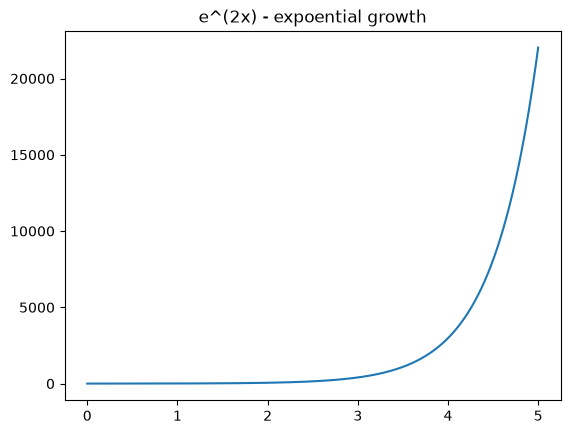

In [40]:
inputs = np.linspace(0, 5, 5000)

outputs = [np.exp(2 * i) for i in  inputs]
plt.title("e^(2x) - expoential growth")

plt.plot(inputs, outputs)
plt.show()

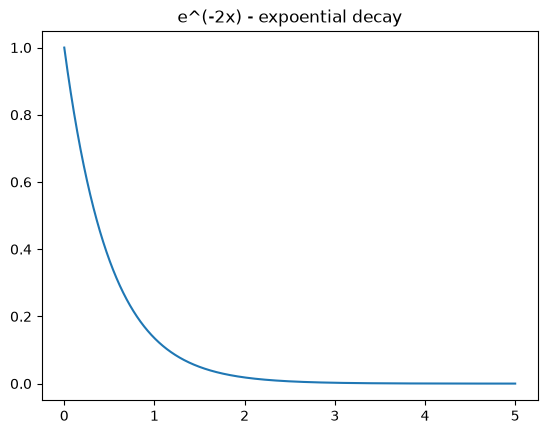

In [41]:
inputs = np.linspace(0, 5, 5000)

outputs = [np.exp(-2 * i) for i in  inputs] 
plt.title("e^(-2x) - expoential decay")


plt.plot(inputs, outputs)
plt.show()

### When s is complex number

When imagianry part of s represnet rotation and when real part is postive it is spiral that both rotates and decays, so it converges ceratin value. When real part is negative values both rotates and grows exponetialy. So on the rigth side of palne values converge, and on the left divergee. On the left side, since values goes into spiral, half of period they are negative and another half postive. Since it is exponetial growth every value is significantly grater than prevoius one, so it is constatn shift between positive and negative values. While at s = 0 it constantly grows.

**Integral converges when the real value of s is positive.**

I need to show why integral is 1/s even for complex values of the postive s plane. For let's just accept that on the right side of input s plane integral is 1/s even for the complex values.

- sp.simplify(expr)	Simplifies the symbolic expression
- expr.evalf()	Evaluates the expression numerically
- sp.N(expr)	Alternative way to evaluate numerically
- sp.Abs(expr)	Calculates the magnitude of a complex expression
- sp.re(expr)	Extracts the real component
- sp.im(expr)	Extracts the imaginary component

In [42]:
t = sp.symbols('t', real=True)
s = -2 + 2 * sp.I

integral_sum = sp.Integral(
    sp.exp(-s * t),
    (t, 0, 2 * sp.pi + 0.5 *sp.pi)
).doit()

display(sp.simplify(integral_sum))
display(integral_sum.evalf())
display(np.abs(integral_sum.evalf()))


-I*(1 - I)*(1 + exp(5.0*pi))/4

-1658906.24983528 - 1658906.24983528*I

2346047.71722255

## When f(t) is an exponetial function

Becasue 1. is equal to 2., and rearanged it is in 3. (code), same integral jsut shifted for a, then it resulting integral when it converges is **1/s -a**. With it everything is shifted for a to the right.

**Poles in the transformed function exposes exponetial pieces of the original** 

In [43]:
s, a = sp.symbols('s a')

f = sp.exp(a * t)

integral_sum = sp.Integral(f * sp.exp(-s * t), (t, 0, sp.oo)).doit()

display(sp.exp(a * t) * sp.exp(-s * t))
display(sp.exp((a -s) * t))
display(sp.exp(-(s - a) * t))

display(sp.Integral(f * sp.exp(-s * t), (t, 0, sp.oo)))
display(integral_sum)

exp(a*t)*exp(-s*t)

exp(t*(a - s))

exp(t*(a - s))

Integral(exp(a*t)*exp(-s*t), (t, 0, oo))

Piecewise((-1/(a*(1 - s/a)), ((Abs(arg(s)) <= pi/2) & (Abs(arg(a) + pi) < pi/2)) | ((Abs(arg(s)) < pi/2) & (Abs(arg(a) + pi) <= pi/2)) | ((Abs(arg(s)) < pi/2) & (Abs(arg(a) + pi) < pi/2))), (Integral(exp(a*t)*exp(-s*t), (t, 0, oo)), True))

### cos(ωt)

- Cos can be expresed as sum of two exponetial fucntions. 
- First equation can be obtained with **Partial Fraction Decompostion** to revela exponetial pieces if it is shown in form of the second equation


In [44]:
omega = sp.symbols('ω')

first_piece = 1/2 * 1/(s - omega)* sp.I # pole at s = omega i
second_piece = 1/2 * 1/(s + omega)* sp.I # pole a s = - omega i

# t, s = sp.symbols('t s')

# F = sp.Integral(sp.exp(-s * t), (t, 0, sp.oo)) # sp.oo is positve infinity

display(sp.Eq(sp.Function('cos')(t * omega), first_piece + second_piece))
#display(sp.Eq(sp.Symbol('s'), s))

display(sp.Eq(sp.Function('cos')(t * omega), s / s**2  + omega**2)) # s / s**2 + ω**2



Eq(cos(t*ω), 0.5*I/(s + ω) + 0.5*I/(s - ω))

Eq(cos(t*ω), ω**2 + 1/s)

## To do: Draw 3D plot with poles

Result from integral is complex number, so it aslo has direction beasides magnitude, so direction information is also important. 17:40 in https://www.youtube.com/watch?v=j0wJBEZdwLs&t=1150s